In [2]:
import numpy as np 
import pandas as pd
import tensorflow
from tensorflow import keras 
from keras import Sequential
from keras.layers import Dense,Dropout

In [3]:
df = pd.read_csv('diabetes.csv')

In [4]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
df.corr()['Outcome']

Pregnancies                 0.221898
Glucose                     0.466581
BloodPressure               0.065068
SkinThickness               0.074752
Insulin                     0.130548
BMI                         0.292695
DiabetesPedigreeFunction    0.173844
Age                         0.238356
Outcome                     1.000000
Name: Outcome, dtype: float64

In [6]:
from sklearn.model_selection import train_test_split
x = df.iloc[:,:-1].values
y = df.iloc[:,-1].values
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=1,stratify=y)


In [7]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [8]:
import keras_tuner as kt

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout

In [9]:
def build_model(hp):

    model = Sequential()

    num_layers = hp.Int('num_layers',min_value=1,max_value=4,step=1)

    for i in range(num_layers):

        units = hp.Int(f'units_{i}',min_value=16,max_value=128,step=16)

        activation = hp.Choice(f'activation_{i}',['relu', 'tanh'])

        if i == 0:
            model.add(Dense(units,activation=activation,input_dim=8))
        else:
            model.add(Dense(units,activation=activation))

        dropout = hp.Float(f'dropout_{i}',min_value=0.0,max_value=0.4,step=0.1)

        model.add(Dropout(dropout))

    
    model.add(Dense(1, activation='sigmoid'))

    optimizer = hp.Choice('optimizer',['adam', 'rmsprop', 'nadam'])

    model.compile(optimizer=optimizer,loss='binary_crossentropy',metrics=['accuracy'])

    return model

In [10]:
x.shape

(768, 8)

In [11]:
tuner = kt.RandomSearch(build_model,objective='val_accuracy',max_trials=20,directory='mydir',project_name='final_diabetes_model')

Reloading Tuner from mydir\final_diabetes_model\tuner0.json


In [12]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [13]:
tuner.search(
    x_train,
    y_train,
    epochs=100,
    validation_split=0.2,
    callbacks=[early_stop]
)

In [14]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print(best_hp.values)

{'num_layers': 4}


In [15]:
best_model.summary()

NameError: name 'best_model' is not defined

In [ ]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print(best_hp.values)

{'num_layers': 5, 'units_0': 16, 'activation_0': 'relu', 'dropout_0': 0.0, 'units_1': 16, 'activation_1': 'relu', 'dropout_1': 0.0, 'units_2': 16, 'activation_2': 'relu', 'dropout_2': 0.0, 'units_3': 16, 'activation_3': 'relu', 'dropout_3': 0.0, 'units_4': 16, 'activation_4': 'relu', 'dropout_4': 0.0, 'optimizer': 'adam'}


In [ ]:
best_model = tuner.hypermodel.build(best_hp)

C:\Users\Hp\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
loss, accuracy = best_model.evaluate(
    x_test,
    y_test
)

print("Test Accuracy:", accuracy)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7273 - loss: 0.5655 
Test Accuracy: 0.7272727489471436


In [ ]:
from sklearn.metrics import classification_report

y_pred = best_model.predict(x_test)

y_pred = (y_pred > 0.5).astype(int)

print(classification_report(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
              precision    recall  f1-score   support

           0       0.74      0.89      0.81       100
           1       0.68      0.43      0.52        54

    accuracy                           0.73       154
   macro avg       0.71      0.66      0.67       154
weighted avg       0.72      0.73      0.71       154



In [ ]:
pip install -U keras-tuner 

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import kerastuner as kt

C:\Users\Hp\AppData\Local\Temp\ipykernel_17620\1654478174.py:1: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  import kerastuner as kt


In [ ]:
history = best_model.fit(
    x_train,
    y_train,
    epochs=100,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.6253 - loss: 0.6854 - val_accuracy: 0.6748 - val_loss: 0.6701
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6660 - loss: 0.6469 - val_accuracy: 0.6341 - val_loss: 0.6507
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6762 - loss: 0.6095 - val_accuracy: 0.6667 - val_loss: 0.6224
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7149 - loss: 0.5694 - val_accuracy: 0.6748 - val_loss: 0.5963
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7556 - loss: 0.5231 - val_accuracy: 0.7317 - val_loss: 0.5602
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7719 - loss: 0.4871 - val_accuracy: 0.7154 - val_loss: 0.5464
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7882 - loss: 0.4619 - val_accuracy: 0.7154 - val_loss: 0.5389
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8004 - loss: 0.4474 - val_accuracy: 0.7236 

In [ ]:
loss, accuracy = best_model.evaluate(x_test, y_test)

print("Test Accuracy:", accuracy)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7597 - loss: 0.5095
Test Accuracy: 0.7597402334213257


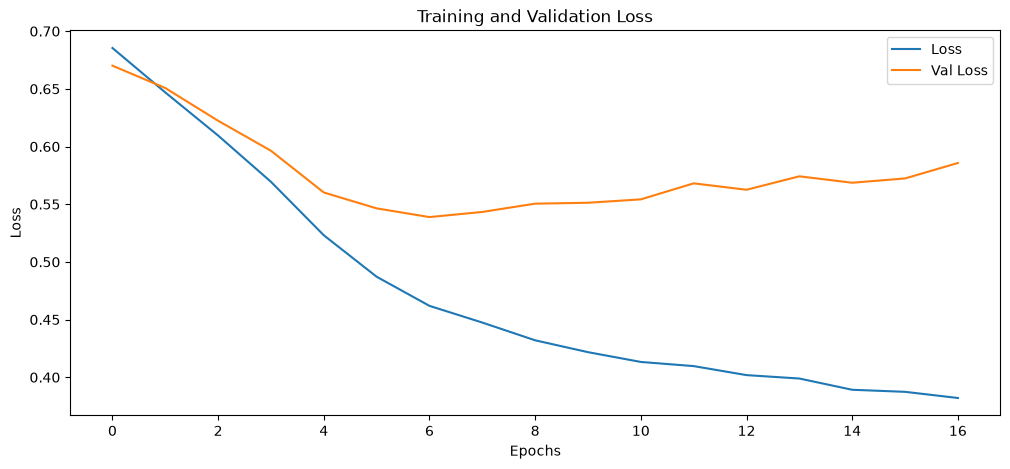

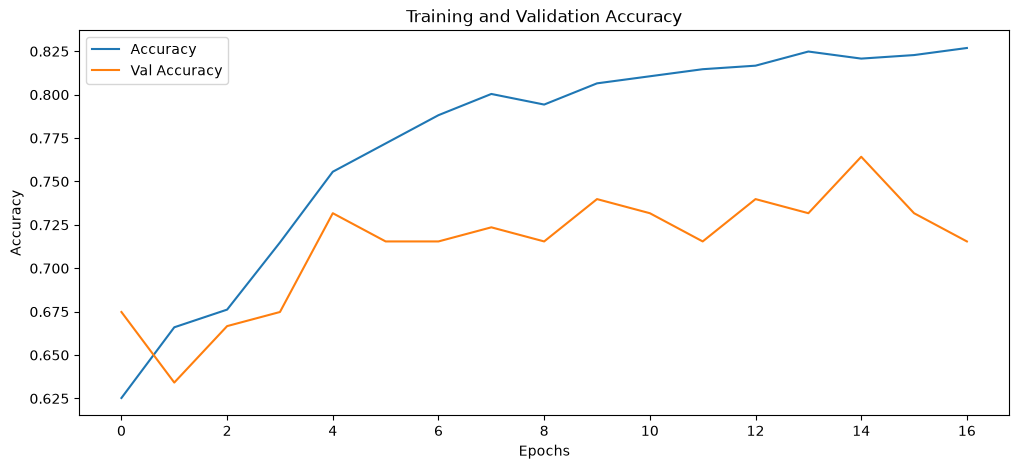

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(history.history['loss'], label='Loss')
plt.plot(history.history['val_loss'], label='Val Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()


plt.figure(figsize=(12, 5))

plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

In [16]:
# Run the summary after your search completes
tuner.results_summary(num_trials=1)


Results summary
Results in mydir\final_diabetes_model
Showing 1 best trials
Objective(name="val_accuracy", direction="max")

Trial 09 summary
Hyperparameters:
num_layers: 4
Score: 0.7642276287078857


In [17]:
# Fetch the best trial objective value
best_score = tuner.oracle.get_best_trials(num_trials=1)[0].score

print(f"Best Validation Accuracy: {best_score}")


Best Validation Accuracy: 0.7642276287078857
